---

# Import Required Libraries

---

In [57]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, r2_score, mean_absolute_error, root_mean_squared_error, silhouette_score
print("Everything is imported successfully!")

Everything is imported successfully!


---

# Preprocess Data

---

## Import & Load Dataset

In [58]:
# Set path
PROJECT_DIR = Path.cwd()
DATASET_PATH = PROJECT_DIR / "datasets" / "data.csv"
if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at: {DATASET_PATH.resolve()}\n"
        f"Current working directory: {PROJECT_DIR.resolve()}"
    )

In [59]:
# Import & load dataset
data = pd.read_csv(DATASET_PATH)
print("Dataset loaded successfully!")
print(f"Dataset path: {DATASET_PATH.resolve()}")

Dataset loaded successfully!
Dataset path: E:\Shabd\Academics\Semester 5\Projects\ML-2026-5CS-E-G1-06\datasets\data.csv


## Dataset Details

In [60]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [61]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [62]:
data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [63]:
data.shape

(614, 13)

In [64]:
data.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [65]:
# Check duplicate records
print("Exact duplicate rows:", data.duplicated().sum())
print("Duplicate Loan_ID values:", data["Loan_ID"].duplicated().sum())
print("Unique Loan_ID values:", data["Loan_ID"].nunique())

Exact duplicate rows: 0
Duplicate Loan_ID values: 0
Unique Loan_ID values: 614


In [66]:
# Inspect categorical features
categorical_columns = data.select_dtypes(include=["object", "str", "category"]).columns.tolist()
for column in categorical_columns:
    print(f"\n{column}")
    print(data[column].value_counts(dropna=False))


Loan_ID
Loan_ID
LP001002    1
LP001003    1
LP001005    1
LP001006    1
LP001008    1
           ..
LP002978    1
LP002979    1
LP002983    1
LP002984    1
LP002990    1
Name: count, Length: 614, dtype: int64

Gender
Gender
Male      489
Female    112
NaN        13
Name: count, dtype: int64

Married
Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64

Dependents
Dependents
0      345
1      102
2      101
3+      51
NaN     15
Name: count, dtype: int64

Education
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

Self_Employed
Self_Employed
No     500
Yes     82
NaN     32
Name: count, dtype: int64

Property_Area
Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64

Loan_Status
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [67]:
# Inspect numerical features
numerical_columns = data.select_dtypes(include=np.number).columns.tolist()
for column in numerical_columns:
    print(f"\n{column}")
    print(data[column].describe())
    print("Unique values:", data[column].nunique())


ApplicantIncome
count      614.000000
mean      5403.459283
std       6109.041673
min        150.000000
25%       2877.500000
50%       3812.500000
75%       5795.000000
max      81000.000000
Name: ApplicantIncome, dtype: float64
Unique values: 505

CoapplicantIncome
count      614.000000
mean      1621.245798
std       2926.248369
min          0.000000
25%          0.000000
50%       1188.500000
75%       2297.250000
max      41667.000000
Name: CoapplicantIncome, dtype: float64
Unique values: 287

LoanAmount
count    592.000000
mean     146.412162
std       85.587325
min        9.000000
25%      100.000000
50%      128.000000
75%      168.000000
max      700.000000
Name: LoanAmount, dtype: float64
Unique values: 203

Loan_Amount_Term
count    600.00000
mean     342.00000
std       65.12041
min       12.00000
25%      360.00000
50%      360.00000
75%      360.00000
max      480.00000
Name: Loan_Amount_Term, dtype: float64
Unique values: 10

Credit_History
count    564.000000
mean     

In [68]:
# Loan approval target distribution
print("Loan_Status value counts:")
print(data["Loan_Status"].value_counts(dropna=False))
print("\nLoan_Status percentage distribution:")
print((data["Loan_Status"].value_counts(normalize=True, dropna=False) * 100).round(2))

Loan_Status value counts:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Loan_Status percentage distribution:
Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64


## Clean Dataset

In [69]:
# Preserve the original dataset for reference
data_clean = data.copy()

In [70]:
# Remove leading/trailing whitespace from column names
data_clean.columns = data_clean.columns.str.strip()

In [71]:
# Remove leading/trailing whitespace from categorical string values
categorical_columns = data_clean.select_dtypes(include=["object", "str", "category"]).columns
for column in categorical_columns:
    data_clean[column] = data_clean[column].map(lambda value: value.strip() if isinstance(value, str) else value)

In [118]:
# Verify the dataset after basic cleaning
print("Dataset shape:", data_clean.shape)
print("Exact duplicate rows:", data_clean.duplicated().sum())
print("\nMissing values:")
print(data_clean.isnull().sum())
print("\nRemaining null values will be automatically handled by pipelines while training & evaluating models later.")

Dataset shape: (614, 16)
Exact duplicate rows: 0

Missing values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
Cluster_k2            0
Cluster_k3            0
Cluster_k4            0
dtype: int64

Remaining null values will be automatically handled by pipelines while training & evaluating models later.


## Define Features & Targets

In [119]:
# Classification: predict historical loan approval status
classification_target = "Loan_Status"
classification_features = data_clean.drop(columns=["Loan_ID", "Loan_Status"])
classification_labels = data_clean[classification_target].copy()

In [120]:
# Regression: predict LoanAmount
regression_data = data_clean.loc[data_clean["LoanAmount"].notna()].copy()
regression_target = regression_data["LoanAmount"].copy()
regression_features = regression_data.drop(columns=["Loan_ID", "Loan_Status", "LoanAmount"])
# Rows with missing LoanAmount will be excluded from this experiment only.

In [121]:
print("Classification features:", classification_features.shape)
print("Classification labels:", classification_labels.shape)
print("\nRegression features:", regression_features.shape)
print("Regression targets:", regression_target.shape)
print("\nRows available for regression:", len(regression_data), "out of", len(data_clean))

Classification features: (614, 14)
Classification labels: (614,)

Regression features: (592, 13)
Regression targets: (592,)

Rows available for regression: 592 out of 614


In [122]:
# Identify numerical & categorical features separately
numerical_features = classification_features.select_dtypes(include=np.number).columns.tolist()
categorical_features = classification_features.select_dtypes(include=["object", "str", "category"]).columns.tolist()

In [123]:
# Dependents is categorical despite representing dependent counts
if "Dependents" in numerical_features:
    numerical_features.remove("Dependents")
    categorical_features.append("Dependents")
print("Numerical features:")
print(numerical_features)
print("\nCategorical features:")
print(categorical_features)

Numerical features:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Cluster_k2', 'Cluster_k3', 'Cluster_k4']

Categorical features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [124]:
# Split classification dataset
RANDOM_STATE = 42
TEST_SIZE = 0.20
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(classification_features, classification_labels,
    test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=classification_labels)
print("Classification Training Features:", X_train_cls.shape)
print("Classification Testing Features:", X_test_cls.shape)
print("Classification Training Labels:", y_train_cls.shape)
print("Classification Testing Labels:", y_test_cls.shape)
print("\nTraining Target Distribution:")
print(y_train_cls.value_counts())
print((y_train_cls.value_counts(normalize=True) * 100).round(2))
print("\nTesting Target Distribution:")
print(y_test_cls.value_counts())
print((y_test_cls.value_counts(normalize=True) * 100).round(2))

Classification Training Features: (491, 14)
Classification Testing Features: (123, 14)
Classification Training Labels: (491,)
Classification Testing Labels: (123,)

Training Target Distribution:
Loan_Status
Y    337
N    154
Name: count, dtype: int64
Loan_Status
Y    68.64
N    31.36
Name: proportion, dtype: float64

Testing Target Distribution:
Loan_Status
Y    85
N    38
Name: count, dtype: int64
Loan_Status
Y    69.11
N    30.89
Name: proportion, dtype: float64


In [125]:
# Split regression dataset
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(regression_features, regression_target, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print("Regression Training Features:", X_train_reg.shape)
print("Regression Testing Features:", X_test_reg.shape)
print("Regression Training Targets:", y_train_reg.shape)
print("Regression Testing Targets:", y_test_reg.shape)

Regression Training Features: (473, 13)
Regression Testing Features: (119, 13)
Regression Training Targets: (473,)
Regression Testing Targets: (119,)


In [126]:
# Identify numerical & categorical features for each task
numerical_features_cls = X_train_cls.select_dtypes(include=np.number).columns.tolist()
categorical_features_cls = X_train_cls.select_dtypes(include=["object", "str", "category"]).columns.tolist()
numerical_features_reg = X_train_reg.select_dtypes(include=np.number).columns.tolist()
categorical_features_reg = X_train_reg.select_dtypes(include=["object", "str", "category"]).columns.tolist()
print("Classification Numerical Features:")
print(numerical_features_cls)
print("\nClassification Categorical Features:")
print(categorical_features_cls)
print("\nRegression Numerical Features:")
print(numerical_features_reg)
print("\nRegression Categorical Features:")
print(categorical_features_reg)

Classification Numerical Features:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Cluster_k2', 'Cluster_k3', 'Cluster_k4']

Classification Categorical Features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']

Regression Numerical Features:
['ApplicantIncome', 'CoapplicantIncome', 'Loan_Amount_Term', 'Credit_History', 'Cluster_k2', 'Cluster_k3', 'Cluster_k4']

Regression Categorical Features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [127]:
# Create preprocessing pipelines
numerical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

In [128]:
# Classification preprocessing
classification_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features_cls),
        ("cat", categorical_transformer, categorical_features_cls)
    ],
    remainder="drop"
)

In [129]:
# Regression preprocessing
regression_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features_reg),
        ("cat", categorical_transformer, categorical_features_reg)
    ],
    remainder="drop"
)

In [130]:
print("Classification and regression preprocessors created successfully.")

Classification and regression preprocessors created successfully.


---

# Train & Evaluate Models

---

## Linear Regression

In [131]:
# Train Linear Regression Model
regression_model = Pipeline(steps=[("preprocessor", regression_preprocessor), ("model", LinearRegression())])
regression_model.fit(X_train_reg, y_train_reg)
y_pred_reg = regression_model.predict(X_test_reg)
print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [161]:
# Evaluate Regression Model
mae = mean_absolute_error(y_test_reg, y_pred_reg)
rmse = root_mean_squared_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)
regression_results = pd.DataFrame({"Metric": ["MAE", "RMSE", "R²"], "Value": [mae, rmse, r2]})
print("Linear Regression Evaluation:")
display(regression_results)

Linear Regression Evaluation:


,Metric,Value
0,MAE,30.599111
1,RMSE,45.836537
2,R²,0.430067


## Classification Evaluation Setup

In [162]:
model_metrics = {}
model_predictions = {}
def evaluate_classifier(model_name, model_pipeline, X_test, y_test):
    """Generate predictions and calculate classification metrics."""
    predictions = pd.Series(model_pipeline.predict(X_test), index=y_test.index, name="Predicted")
    model_predictions[model_name] = predictions
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, pos_label="Y", zero_division=0),
        "Recall": recall_score(y_test, predictions, pos_label="Y", zero_division=0),
        "F1-Score": f1_score(y_test, predictions, pos_label="Y", zero_division=0)
    }
    model_metrics[model_name] = metrics
    print(f"Evaluation Results: {model_name}")
    print(f"Accuracy:  {metrics['Accuracy']:.4f}")
    print(f"Precision: {metrics['Precision']:.4f}")
    print(f"Recall:    {metrics['Recall']:.4f}")
    print(f"F1-Score:  {metrics['F1-Score']:.4f}")
    print("\nDetailed Classification Report:")
    print(classification_report(y_test, predictions, labels=["N", "Y"], target_names=["Not Approved (N)", "Approved (Y)"], zero_division=0))
    return predictions

In [163]:
# Show Correct & Incorrect classification predictions
def show_classifier_diagnostics(model_name, predictions, X_test, y_test):
    results = X_test.copy()
    results["Actual"] = np.asarray(y_test).ravel()
    results["Predicted"] = np.asarray(predictions).ravel()
    results["Correct"] = results["Actual"] == results["Predicted"]
    # Fill missing values in displayed rows for readability
    results_display = results.copy()
    for column in results_display.columns:
        if column in ["Actual", "Predicted", "Correct"]:
            continue
        if results_display[column].isnull().any():
            if pd.api.types.is_numeric_dtype(results_display[column]):
                fill_value = results_display[column].median()
            else:
                mode_values = results_display[column].mode()
                fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
            results_display[column] = results_display[column].fillna(fill_value)
    print(f"{model_name} - Correct Predictions:")
    display(results_display[results_display["Correct"]].head())
    print(f"{model_name} - Incorrect Predictions:")
    display(results_display[~results_display["Correct"]].head())

## KNN

In [164]:
# Train KNN Model
knn_pipeline = Pipeline(steps=[("preprocessor", clone(classification_preprocessor)), ("model", KNeighborsClassifier(n_neighbors=5))])
knn_pipeline.fit(X_train_cls, y_train_cls)
print("KNN model trained successfully.")

KNN model trained successfully.


In [165]:
# Evaluate KNN Model
knn_predictions = evaluate_classifier("KNN", knn_pipeline, X_test_cls, y_test_cls)

Evaluation Results: KNN
Accuracy:  0.8537
Precision: 0.8384
Recall:    0.9765
F1-Score:  0.9022

Detailed Classification Report:
                  precision    recall  f1-score   support

Not Approved (N)       0.92      0.58      0.71        38
    Approved (Y)       0.84      0.98      0.90        85

        accuracy                           0.85       123
       macro avg       0.88      0.78      0.81       123
    weighted avg       0.86      0.85      0.84       123



## Gaussian Naive Bayes

In [166]:
# Train Gaussian Naive Bayes Model
gnb_pipeline = Pipeline(steps=[("preprocessor", clone(classification_preprocessor)), ("model", GaussianNB())])
gnb_pipeline.fit(X_train_cls, y_train_cls)
print("Gaussian Naive Bayes model trained successfully.")

Gaussian Naive Bayes model trained successfully.


In [167]:
# Evaluate Gaussian Naive Bayes Model
gnb_predictions = evaluate_classifier("Gaussian Naive Bayes", gnb_pipeline, X_test_cls, y_test_cls)

Evaluation Results: Gaussian Naive Bayes
Accuracy:  0.8537
Precision: 0.8526
Recall:    0.9529
F1-Score:  0.9000

Detailed Classification Report:
                  precision    recall  f1-score   support

Not Approved (N)       0.86      0.63      0.73        38
    Approved (Y)       0.85      0.95      0.90        85

        accuracy                           0.85       123
       macro avg       0.85      0.79      0.81       123
    weighted avg       0.85      0.85      0.85       123



## SVC

In [168]:
# Train SVM Linear Model
svm_linear_pipeline = Pipeline(steps=[("preprocessor", clone(classification_preprocessor)), ("model", SVC(kernel="linear", random_state=RANDOM_STATE))])
svm_linear_pipeline.fit(X_train_cls, y_train_cls)
print("Linear SVM model trained successfully.")

Linear SVM model trained successfully.


In [169]:
# Evaluate SVM Linear Model
svm_linear_predictions = evaluate_classifier("SVM - Linear", svm_linear_pipeline, X_test_cls, y_test_cls)

Evaluation Results: SVM - Linear
Accuracy:  0.8537
Precision: 0.8317
Recall:    0.9882
F1-Score:  0.9032

Detailed Classification Report:
                  precision    recall  f1-score   support

Not Approved (N)       0.95      0.55      0.70        38
    Approved (Y)       0.83      0.99      0.90        85

        accuracy                           0.85       123
       macro avg       0.89      0.77      0.80       123
    weighted avg       0.87      0.85      0.84       123



In [170]:
# Train SVM Polynomial Model
svm_poly_pipeline = Pipeline(steps=[("preprocessor", clone(classification_preprocessor)), ("model", SVC(kernel="poly", degree=3, random_state=RANDOM_STATE))])
svm_poly_pipeline.fit(X_train_cls, y_train_cls)
print("Polynomial SVM model trained successfully.")

Polynomial SVM model trained successfully.


In [171]:
# Evaluate SVM Polynomial Model
svm_poly_predictions = evaluate_classifier("SVM - Polynomial", svm_poly_pipeline, X_test_cls, y_test_cls)

Evaluation Results: SVM - Polynomial
Accuracy:  0.8537
Precision: 0.8317
Recall:    0.9882
F1-Score:  0.9032

Detailed Classification Report:
                  precision    recall  f1-score   support

Not Approved (N)       0.95      0.55      0.70        38
    Approved (Y)       0.83      0.99      0.90        85

        accuracy                           0.85       123
       macro avg       0.89      0.77      0.80       123
    weighted avg       0.87      0.85      0.84       123



In [172]:
# Train SVM RBF Model
svm_rbf_pipeline = Pipeline(steps=[("preprocessor", clone(classification_preprocessor)), ("model", SVC(kernel="rbf", random_state=RANDOM_STATE))])
svm_rbf_pipeline.fit(X_train_cls, y_train_cls)
print("RBF SVM model trained successfully.")

RBF SVM model trained successfully.


In [173]:
# Evaluate SVM RBF Model
svm_rbf_predictions = evaluate_classifier("SVM - RBF", svm_rbf_pipeline, X_test_cls, y_test_cls)

Evaluation Results: SVM - RBF
Accuracy:  0.8455
Precision: 0.8235
Recall:    0.9882
F1-Score:  0.8984

Detailed Classification Report:
                  precision    recall  f1-score   support

Not Approved (N)       0.95      0.53      0.68        38
    Approved (Y)       0.82      0.99      0.90        85

        accuracy                           0.85       123
       macro avg       0.89      0.76      0.79       123
    weighted avg       0.86      0.85      0.83       123



## Decision Tree

In [174]:
# Train Decision Tree Model
dt_pipeline = Pipeline(steps=[("preprocessor", clone(classification_preprocessor)), ("model", DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE))])
dt_pipeline.fit(X_train_cls, y_train_cls)
dt_predictions = dt_pipeline.predict(X_test_cls)
print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [175]:
# Evaluate Decision Tree Model
dt_metrics = {
    "Model": "Decision Tree (Entropy)",
    "Accuracy": accuracy_score(y_test_cls, dt_predictions),
    "Precision": precision_score(y_test_cls, dt_predictions, pos_label="Y", zero_division=0),
    "Recall": recall_score(y_test_cls, dt_predictions, pos_label="Y", zero_division=0),
    "F1-Score": f1_score(y_test_cls, dt_predictions, pos_label="Y", zero_division=0)
}
dt_results = pd.DataFrame([dt_metrics])
print("Decision Tree Evaluation:")
display(dt_results.round(4))

Decision Tree Evaluation:


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree (Entropy),0.7236,0.8228,0.7647,0.7927


In [176]:
# Evaluate Decision Tree Model
dt_predictions = evaluate_classifier("Decision Tree (Entropy)", dt_pipeline, X_test_cls, y_test_cls)

Evaluation Results: Decision Tree (Entropy)
Accuracy:  0.7236
Precision: 0.8228
Recall:    0.7647
F1-Score:  0.7927

Detailed Classification Report:
                  precision    recall  f1-score   support

Not Approved (N)       0.55      0.63      0.59        38
    Approved (Y)       0.82      0.76      0.79        85

        accuracy                           0.72       123
       macro avg       0.68      0.70      0.69       123
    weighted avg       0.74      0.72      0.73       123



## Random Forest

In [177]:
# Train Random Forest Models (Different Numbers Of Trees)
num_trees = [1, 5, 10, 20, 50, 100, 250, 500, 1000]
rf_results = []
for num in num_trees:
    rf_model = Pipeline(steps=[
        ("preprocessor", clone(classification_preprocessor)),
        ("model", RandomForestClassifier(n_estimators=num, random_state=RANDOM_STATE))
    ])
    rf_model.fit(X_train_cls, y_train_cls)
    y_pred_rf = rf_model.predict(X_test_cls)
    rf_results.append({
        "Number of Trees": num,
        "Accuracy": accuracy_score(y_test_cls, y_pred_rf),
        "Precision": precision_score(y_test_cls, y_pred_rf, pos_label="Y", zero_division=0),
        "Recall": recall_score(y_test_cls, y_pred_rf, pos_label="Y", zero_division=0),
        "F1-Score": f1_score(y_test_cls, y_pred_rf, pos_label="Y", zero_division=0)
    })
rf_results = pd.DataFrame(rf_results)
print("Random Forest models trained and evaluated successfully.")

Random Forest models trained and evaluated successfully.


In [178]:
# Evaluate Random Forest Models
print("Random Forest Evaluation:")
display(rf_results.round(4))

Random Forest Evaluation:


,Number of Trees,Accuracy,Precision,Recall,F1-Score
0,1,0.7073,0.7816,0.8000,0.7907
1,5,0.7561,0.8235,0.8235,0.8235
2,10,0.7561,0.8235,0.8235,0.8235
3,20,0.7886,0.8471,0.8471,0.8471
4,50,0.8211,0.8621,0.8824,0.8721
5,100,0.8211,0.8539,0.8941,0.8736
6,250,0.8211,0.8462,0.9059,0.8750
7,500,0.8211,0.8462,0.9059,0.8750
8,1000,0.8211,0.8387,0.9176,0.8764


## K Means Clustering

In [179]:
# Train K-Means Model
clustering_features = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]
clustering_data = data_clean[clustering_features].copy()
clustering_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
X_cluster_scaled = clustering_preprocessor.fit_transform(clustering_data)
kmeans_models = {}
cluster_results = []
for k in [2, 3, 4]:
    kmeans_model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    cluster_labels = kmeans_model.fit_predict(X_cluster_scaled)
    kmeans_models[k] = kmeans_model
    cluster_results.append({
        "Number of Clusters (k)": k,
        "Inertia": kmeans_model.inertia_,
        "Silhouette Score": silhouette_score(X_cluster_scaled, cluster_labels)
    })
    data_clean[f"Cluster_k{k}"] = cluster_labels
print("K-Means clustering completed successfully for k = 2, 3, and 4.")

e:\Shabd\Academics\Semester 5\Projects\ML-2026-5CS-E-G1-06\.venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
e:\Shabd\Academics\Semester 5\Projects\ML-2026-5CS-E-G1-06\.venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


K-Means clustering completed successfully for k = 2, 3, and 4.


e:\Shabd\Academics\Semester 5\Projects\ML-2026-5CS-E-G1-06\.venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


In [190]:
# Evaluate K-Means Model
cluster_evaluation = pd.DataFrame(cluster_results)
print("K-Means Clustering Evaluation:")
display(cluster_evaluation.round(4))

K-Means Clustering Evaluation:


,Number of Clusters (k),Inertia,Silhouette Score
0,2,1273.7924,0.7332
1,3,920.6850,0.7416
2,4,707.8739,0.4592


---

# Data Visualization

---

## Linear Regression: Actual vs Predicted Loan Amounts

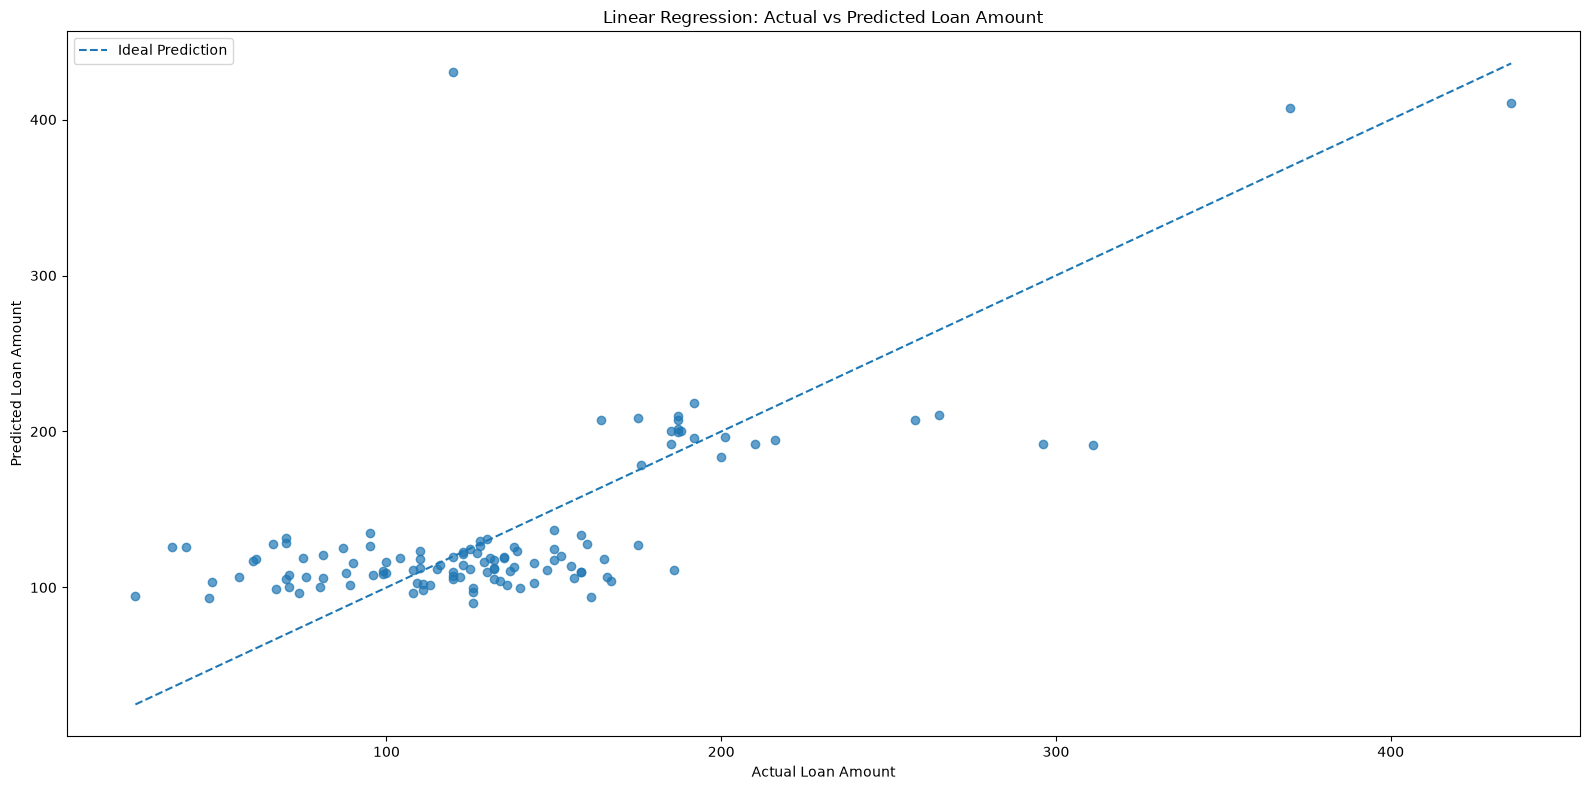

In [191]:
plt.figure(figsize=(16, 8))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.7)
plot_min = min(y_test_reg.min(), y_pred_reg.min())
plot_max = max(y_test_reg.max(), y_pred_reg.max())
plt.plot([plot_min, plot_max], [plot_min, plot_max], linestyle="--", label="Ideal Prediction")
plt.xlabel("Actual Loan Amount")
plt.ylabel("Predicted Loan Amount")
plt.title("Linear Regression: Actual vs Predicted Loan Amount")
plt.legend()
plt.tight_layout()
plt.show()

## KNN: Confusion Matrix & Predictions

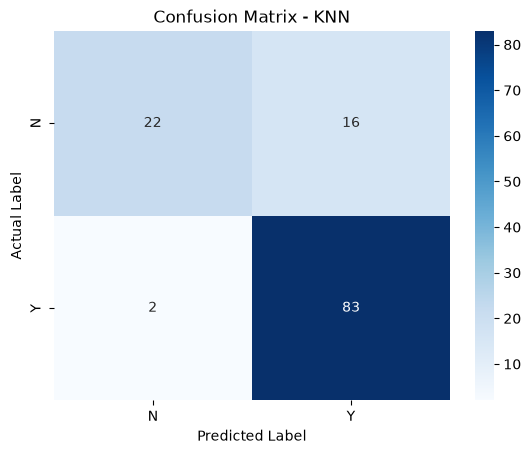

In [192]:
# Confusion Matrix
cm_knn = confusion_matrix(y_test_cls, knn_predictions)
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues", xticklabels=["N", "Y"], yticklabels=["N", "Y"])
plt.title("Confusion Matrix - KNN")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [193]:
show_classifier_diagnostics("KNN", knn_predictions, X_test_cls, y_test_cls)

KNN - Correct Predictions:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Cluster_k2,Cluster_k3,Cluster_k4,Actual,Predicted,Correct
150,Male,No,0,Graduate,No,6277,0.0,118.0,360.0,0.0,Rural,1,0,0,N,N,True
559,Female,Yes,0,Graduate,No,4180,2306.0,182.0,360.0,1.0,Semiurban,1,0,3,Y,Y,True
598,Male,Yes,0,Graduate,Yes,9963,0.0,180.0,360.0,1.0,Rural,1,0,3,Y,Y,True
235,Male,Yes,1,Graduate,No,5500,1260.0,170.0,360.0,1.0,Rural,1,0,0,Y,Y,True
145,Female,Yes,0,Graduate,No,2330,4486.0,100.0,360.0,1.0,Semiurban,1,0,0,Y,Y,True


KNN - Incorrect Predictions:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Cluster_k2,Cluster_k3,Cluster_k4,Actual,Predicted,Correct
88,Male,No,0,Graduate,No,8566,0.0,210.0,360.0,1.0,Urban,1,0,3,Y,N,False
326,Male,No,0,Graduate,No,4917,0.0,130.0,360.0,0.0,Rural,1,0,0,Y,N,False
268,Female,No,0,Graduate,No,3418,0.0,135.0,360.0,1.0,Rural,1,0,0,N,Y,False
479,Male,Yes,2,Graduate,No,2947,1603.0,123.0,360.0,1.0,Urban,1,0,0,N,Y,False
216,Male,Yes,0,Graduate,No,150,1800.0,135.0,360.0,1.0,Rural,1,0,0,N,Y,False


## Gaussian Naive Bayes: Confusion Matrix & Predictions

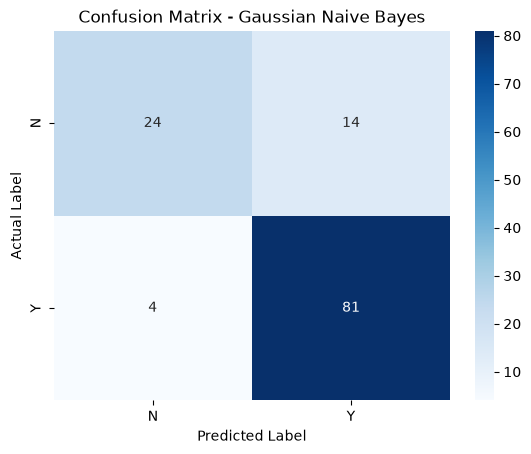

In [200]:
# Confusion Matrix
cm_nb = confusion_matrix(y_test_cls, gnb_predictions)
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Blues", xticklabels=["N", "Y"], yticklabels=["N", "Y"])
plt.title("Confusion Matrix - Gaussian Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [201]:
show_classifier_diagnostics("Gaussian Naive Bayes", gnb_predictions, X_test_cls, y_test_cls)

Gaussian Naive Bayes - Correct Predictions:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Cluster_k2,Cluster_k3,Cluster_k4,Actual,Predicted,Correct
150,Male,No,0,Graduate,No,6277,0.0,118.0,360.0,0.0,Rural,1,0,0,N,N,True
559,Female,Yes,0,Graduate,No,4180,2306.0,182.0,360.0,1.0,Semiurban,1,0,3,Y,Y,True
598,Male,Yes,0,Graduate,Yes,9963,0.0,180.0,360.0,1.0,Rural,1,0,3,Y,Y,True
235,Male,Yes,1,Graduate,No,5500,1260.0,170.0,360.0,1.0,Rural,1,0,0,Y,Y,True
145,Female,Yes,0,Graduate,No,2330,4486.0,100.0,360.0,1.0,Semiurban,1,0,0,Y,Y,True


Gaussian Naive Bayes - Incorrect Predictions:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Cluster_k2,Cluster_k3,Cluster_k4,Actual,Predicted,Correct
191,Male,No,0,Graduate,No,12000,0.0,164.0,360.0,1.0,Semiurban,1,0,3,N,Y,False
185,Male,Yes,0,Graduate,Yes,39147,4750.0,120.0,360.0,1.0,Semiurban,0,1,2,Y,N,False
326,Male,No,0,Graduate,No,4917,0.0,130.0,360.0,0.0,Rural,1,0,0,Y,N,False
268,Female,No,0,Graduate,No,3418,0.0,135.0,360.0,1.0,Rural,1,0,0,N,Y,False
479,Male,Yes,2,Graduate,No,2947,1603.0,123.0,360.0,1.0,Urban,1,0,0,N,Y,False


## SVM Classifier: Comparisons

In [202]:
# Table
svm_results = pd.DataFrame([
    {
        "Kernel": "Linear",
        "Accuracy": accuracy_score(y_test_cls, svm_linear_predictions),
        "Precision": precision_score(y_test_cls, svm_linear_predictions, pos_label="Y", zero_division=0),
        "Recall": recall_score(y_test_cls, svm_linear_predictions, pos_label="Y", zero_division=0),
        "F1-Score": f1_score(y_test_cls, svm_linear_predictions, pos_label="Y", zero_division=0)
    },
    {
        "Kernel": "Polynomial",
        "Accuracy": accuracy_score(y_test_cls, svm_poly_predictions),
        "Precision": precision_score(y_test_cls, svm_poly_predictions, pos_label="Y", zero_division=0),
        "Recall": recall_score(y_test_cls, svm_poly_predictions, pos_label="Y", zero_division=0),
        "F1-Score": f1_score(y_test_cls, svm_poly_predictions, pos_label="Y", zero_division=0)
    },
    {
        "Kernel": "RBF",
        "Accuracy": accuracy_score(y_test_cls, svm_rbf_predictions),
        "Precision": precision_score(y_test_cls, svm_rbf_predictions, pos_label="Y", zero_division=0),
        "Recall": recall_score(y_test_cls, svm_rbf_predictions, pos_label="Y", zero_division=0),
        "F1-Score": f1_score(y_test_cls, svm_rbf_predictions, pos_label="Y", zero_division=0)
    }
])
print("SVM Kernel Comparison:")
display(svm_results.round(4))

SVM Kernel Comparison:


,Kernel,Accuracy,Precision,Recall,F1-Score
0,Linear,0.8537,0.8317,0.9882,0.9032
1,Polynomial,0.8537,0.8317,0.9882,0.9032
2,RBF,0.8455,0.8235,0.9882,0.8984


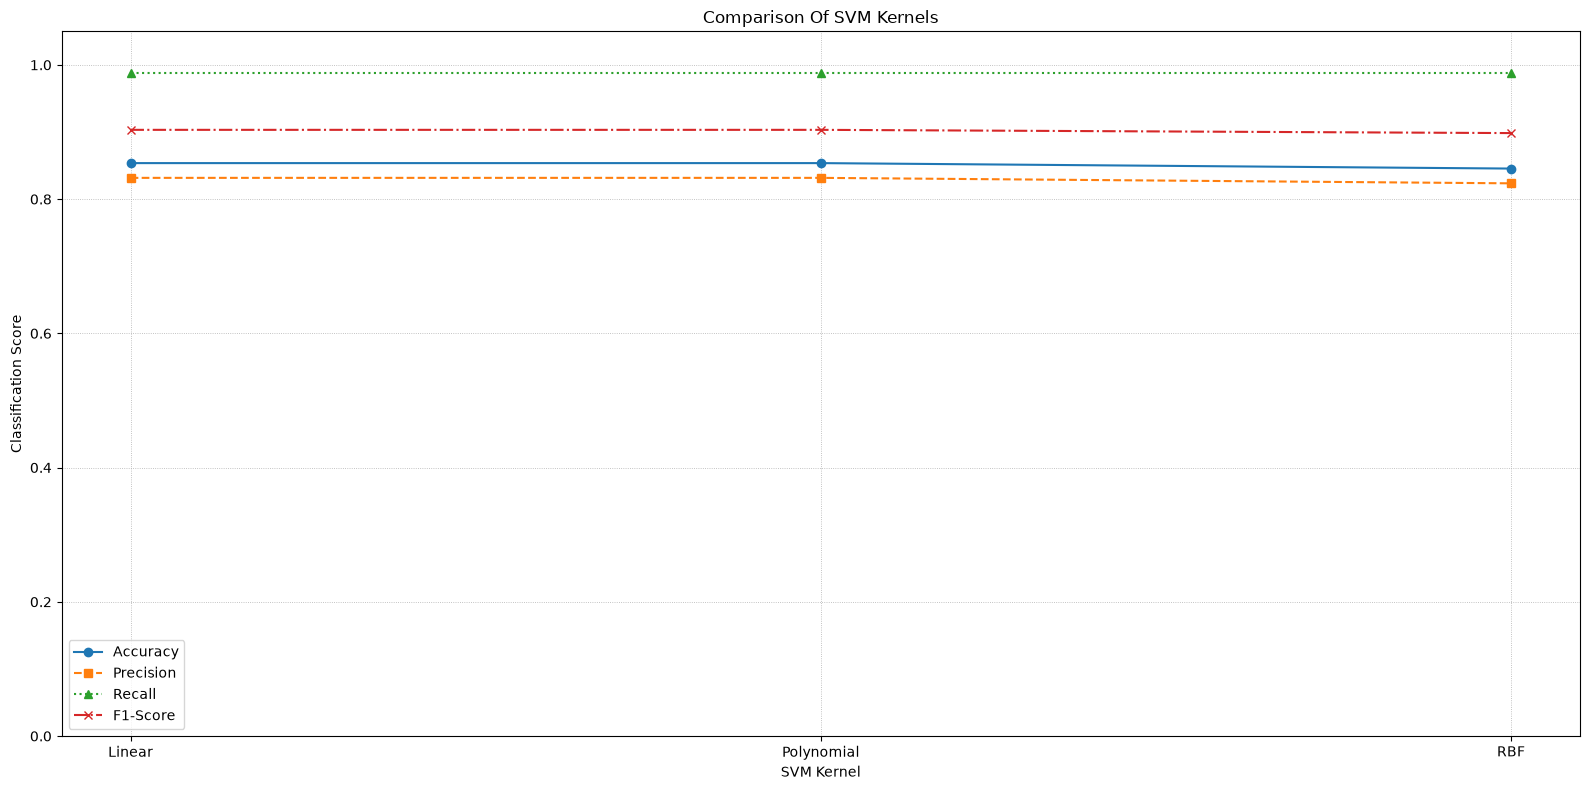

In [211]:
# Plot
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
markers = ["o", "s", "^", "x"]
line_styles = ["-", "--", ":", "-."]
plt.figure(figsize=(16, 8))
for metric, marker, line_style in zip(metrics, markers, line_styles):
    plt.plot(svm_results["Kernel"], svm_results[metric], marker=marker, linestyle=line_style, label=metric)
plt.xlabel("SVM Kernel")
plt.ylabel("Classification Score")
plt.title("Comparison Of SVM Kernels")
plt.ylim(0, 1.05)
plt.grid(True, linestyle=":", linewidth=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## Decision Tree: Confusion Matrix

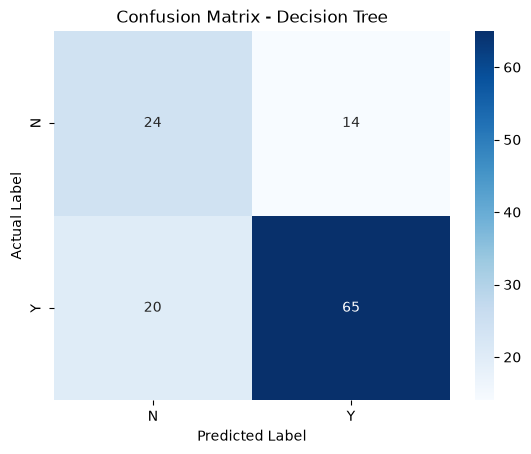

In [213]:
cm_dt = confusion_matrix(y_test_cls, dt_predictions)
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues", xticklabels=["N", "Y"], yticklabels=["N", "Y"])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Decision Tree")
plt.show()

## Random Forest: Classification Scores vs. Number Of Trees

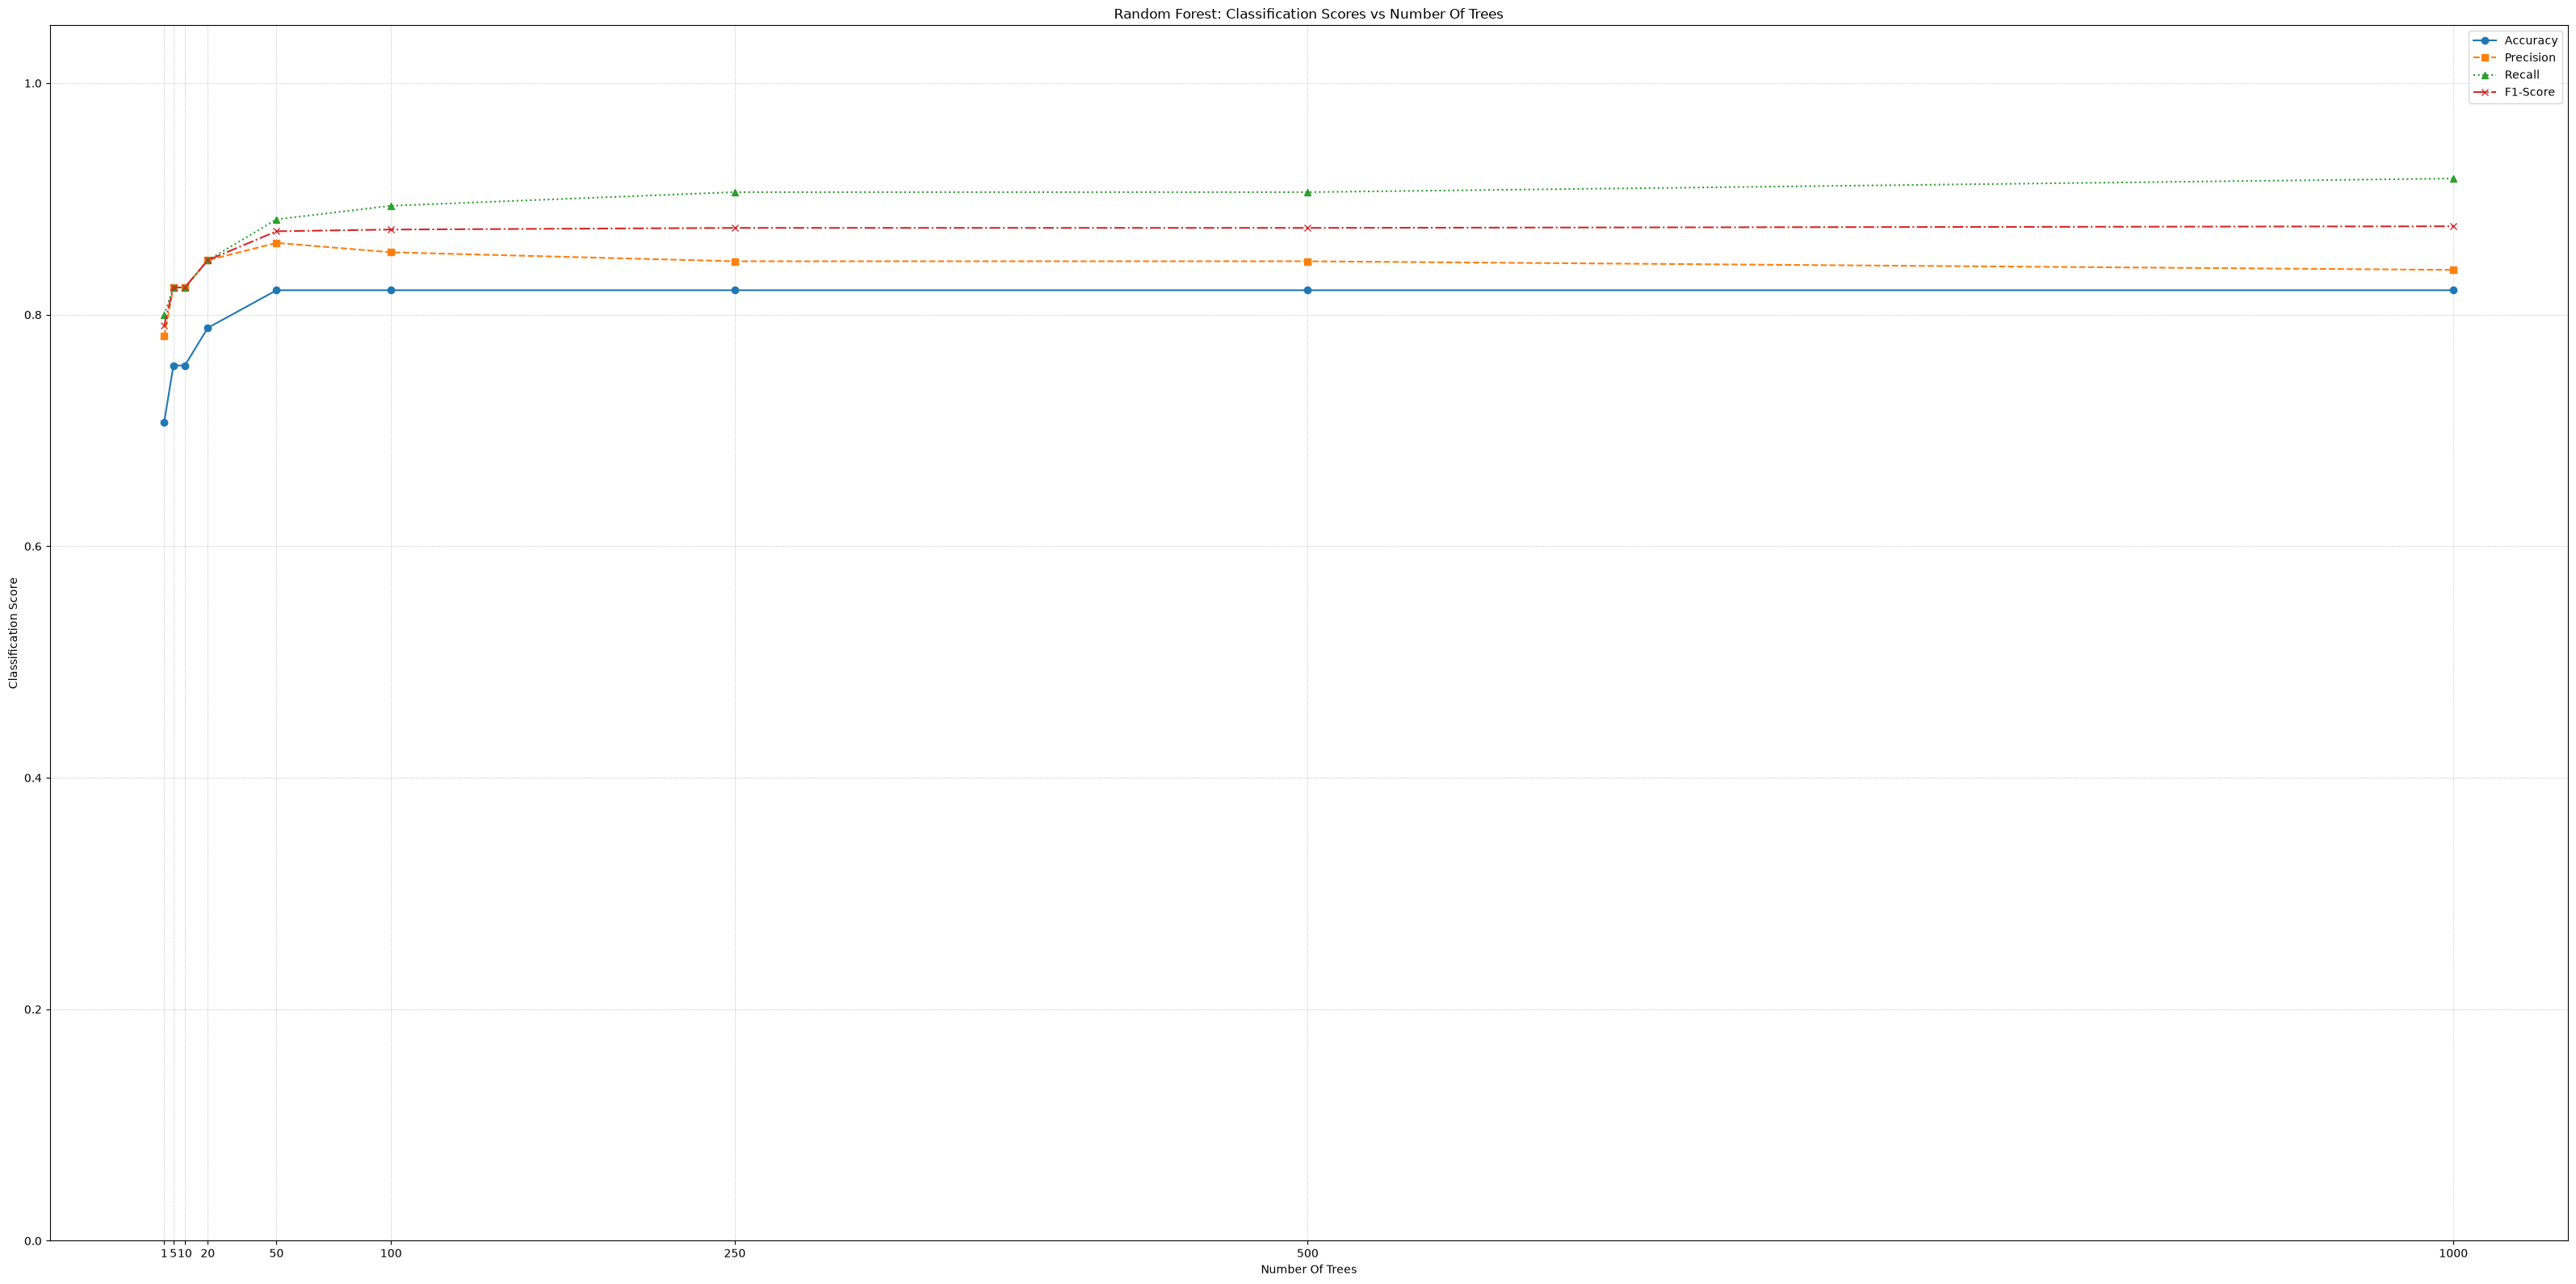

In [218]:
plt.figure(figsize=(32, 16))
plt.plot(rf_results["Number of Trees"], rf_results["Accuracy"], linestyle="-", marker="o", label="Accuracy")
plt.plot(rf_results["Number of Trees"], rf_results["Precision"], linestyle="--", marker="s", label="Precision")
plt.plot(rf_results["Number of Trees"], rf_results["Recall"], linestyle=":", marker="^", label="Recall")
plt.plot(rf_results["Number of Trees"], rf_results["F1-Score"], linestyle="-.", marker="x", label="F1-Score")
plt.xlabel("Number Of Trees")
plt.ylabel("Classification Score")
plt.title("Random Forest: Classification Scores vs Number Of Trees")
plt.xticks(num_trees)
plt.ylim(0, 1.05)
plt.grid(True, linestyle=":", linewidth=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## K Means: Cluster Profiles

Average financial characteristics for k = 2:


,ApplicantIncome,CoapplicantIncome,LoanAmount
Cluster_k2,,,
0,19642.72,4931.25,385.44
1,4516.58,1415.09,130.94


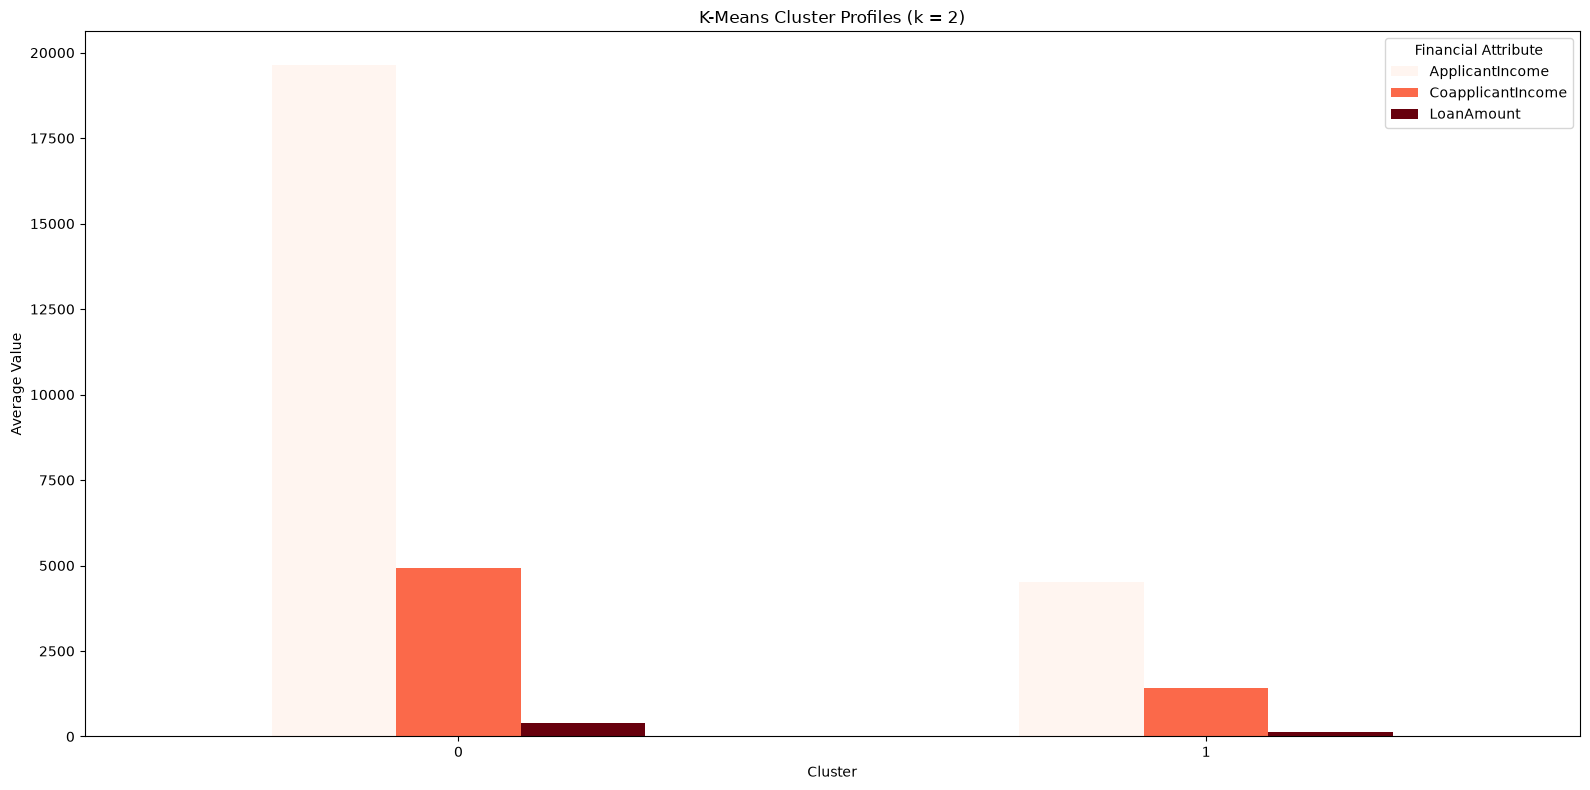

Average financial characteristics for k = 3:


,ApplicantIncome,CoapplicantIncome,LoanAmount
Cluster_k3,,,
0,4545.97,1401.83,132.65
1,23771.96,2288.32,414.57
2,1588.00,28876.00,195.50


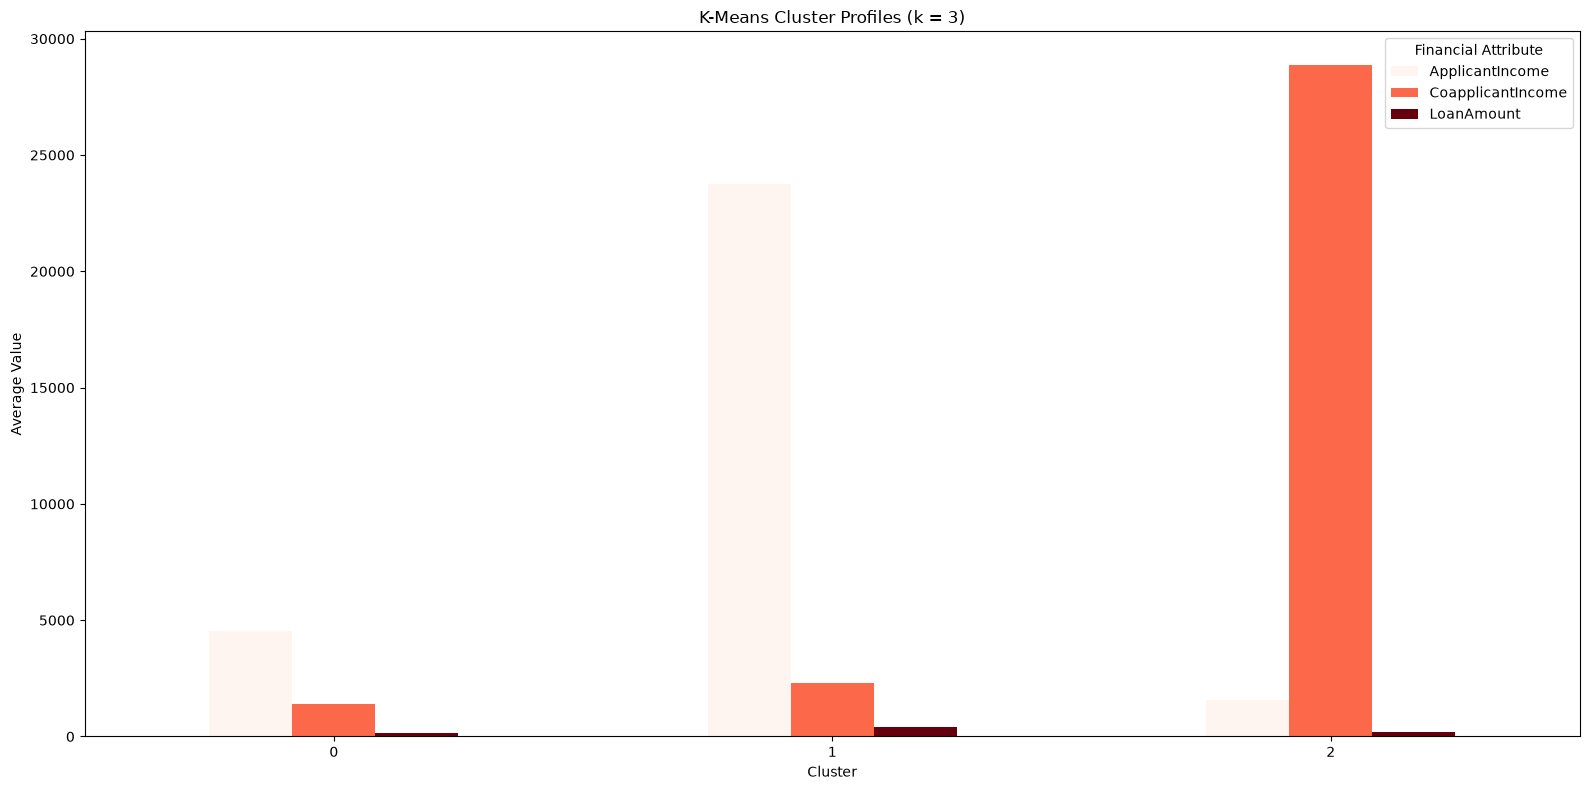

Average financial characteristics for k = 4:


,ApplicantIncome,CoapplicantIncome,LoanAmount
Cluster_k4,,,
0,3877.55,1208.57,112.75
1,1588.00,28876.00,195.50
2,34956.64,1191.64,452.29
3,7965.21,2352.16,232.47


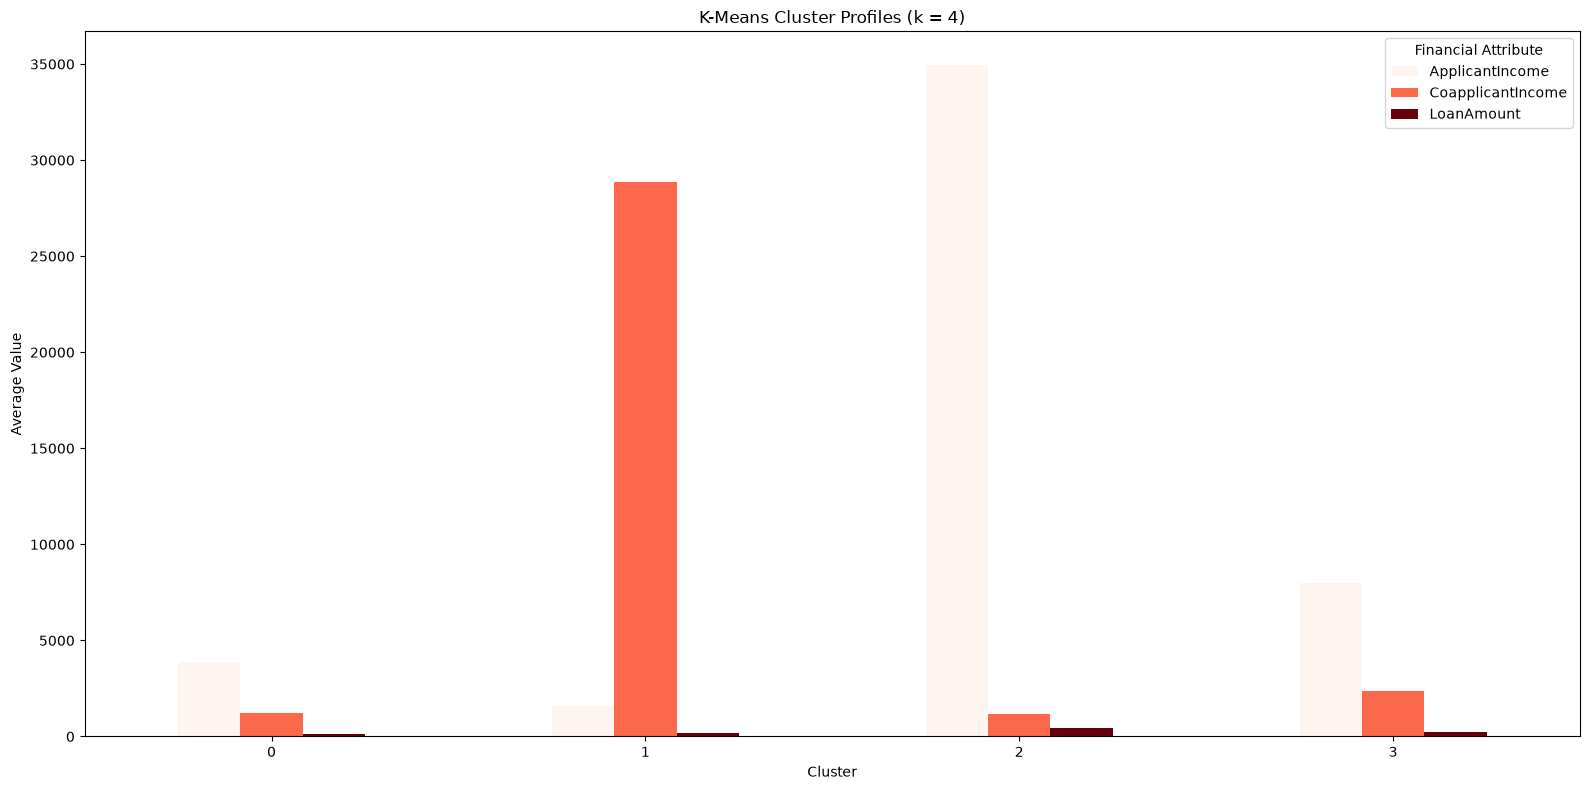

In [222]:
for k in [2, 3, 4]:
    cluster_column = f"Cluster_k{k}"
    cluster_profile = data_clean.groupby(cluster_column)[clustering_features].mean()
    print(f"Average financial characteristics for k = {k}:")
    display(cluster_profile.round(2))
    cluster_profile.plot(kind="bar", figsize=(16, 8), colormap="Reds")
    plt.xlabel("Cluster")
    plt.ylabel("Average Value")
    plt.title(f"K-Means Cluster Profiles (k = {k})")
    plt.xticks(rotation=0)
    plt.legend(title="Financial Attribute")
    plt.tight_layout()
    plt.show()